In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

X = pd.read_parquet(
    "../Results/X_final.parquet"
)

y = pd.read_parquet(
    "../Results/y_final.parquet"
)["BinaryLabel"]

print(X.shape)
print(y.shape)

(2313810, 48)
(2313810,)


# Train/Test

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

print("\nTraining distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting distribution:")
print(y_test.value_counts(normalize=True))

Training: (1851048, 48)
Testing : (462762, 48)

Training distribution:
BinaryLabel
1    0.801699
0    0.198301
Name: proportion, dtype: float64

Testing distribution:
BinaryLabel
1    0.801699
0    0.198301
Name: proportion, dtype: float64


# Random Forest

In [3]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf.fit(
    X_train,
    y_train
)

print("Random Forest training completed.")

Random Forest training completed.


# Prediction

In [4]:
y_pred_rf = rf.predict(X_test)

print(
    "Prediction completed."
)

print(
    "Prediction shape:",
    y_pred_rf.shape
)

Prediction completed.
Prediction shape: (462762,)


# Metrics

In [5]:
rf_accuracy = accuracy_score(
    y_test,
    y_pred_rf
)

rf_precision = precision_score(
    y_test,
    y_pred_rf,
    zero_division=0
)

rf_recall = recall_score(
    y_test,
    y_pred_rf,
    zero_division=0
)

rf_f1 = f1_score(
    y_test,
    y_pred_rf,
    zero_division=0
)

print("Random Forest Results")
print("=" * 20)

print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1-score : {rf_f1:.4f}")

Random Forest Results
Accuracy : 0.7894
Precision: 0.8770
Recall   : 0.8577
F1-score : 0.8672


# Classification report

In [6]:
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=[
            "Benign",
            "Attack"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Benign       0.47      0.51      0.49     91766
      Attack       0.88      0.86      0.87    370996

    accuracy                           0.79    462762
   macro avg       0.67      0.69      0.68    462762
weighted avg       0.80      0.79      0.79    462762



# Confusion Matrix

In [14]:
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf
)
print(cm_rf)

[[ 47120  44646]
 [ 52805 318191]]


# Visualization

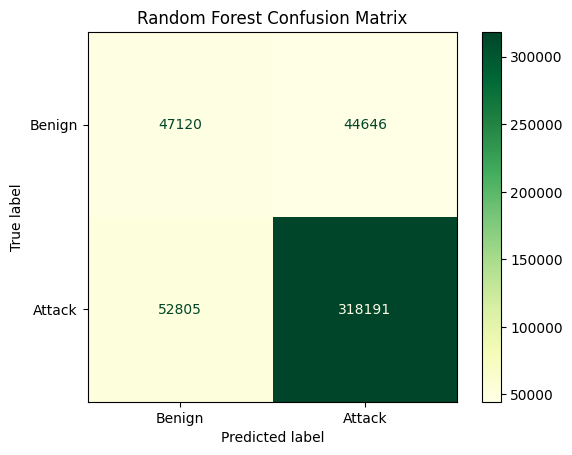

In [11]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=[
        "Benign",
        "Attack"
    ]
)

disp.plot(cmap='YlGn')
plt.title("Random Forest Confusion Matrix")
plt.show()

# False Positive Rate

In [15]:
tn, fp, fn, tp = cm_rf.ravel()

rf_fpr = fp / (fp + tn)

print("True Negative :", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive :", tp)

print(
    f"\nFalse Positive Rate: {rf_fpr:.4f}"
)

True Negative : 47120
False Positive: 44646
False Negative: 52805
True Positive : 318191

False Positive Rate: 0.4865


# Feature Importance

In [16]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

display(
    importance.head(30)
)

,Feature,Importance
13,Flow IAT Max,0.080890
38,Init Fwd Win Bytes,0.064650
9,Flow Bytes/s,0.052469
1,Flow Duration,0.051641
11,Flow IAT Mean,0.049204
10,Flow Packets/s,0.048780
27,Bwd Packets/s,0.044893
31,Packet Length Variance,0.043092
12,Flow IAT Std,0.038812
30,Packet Length Mean,0.035635


# Visualization

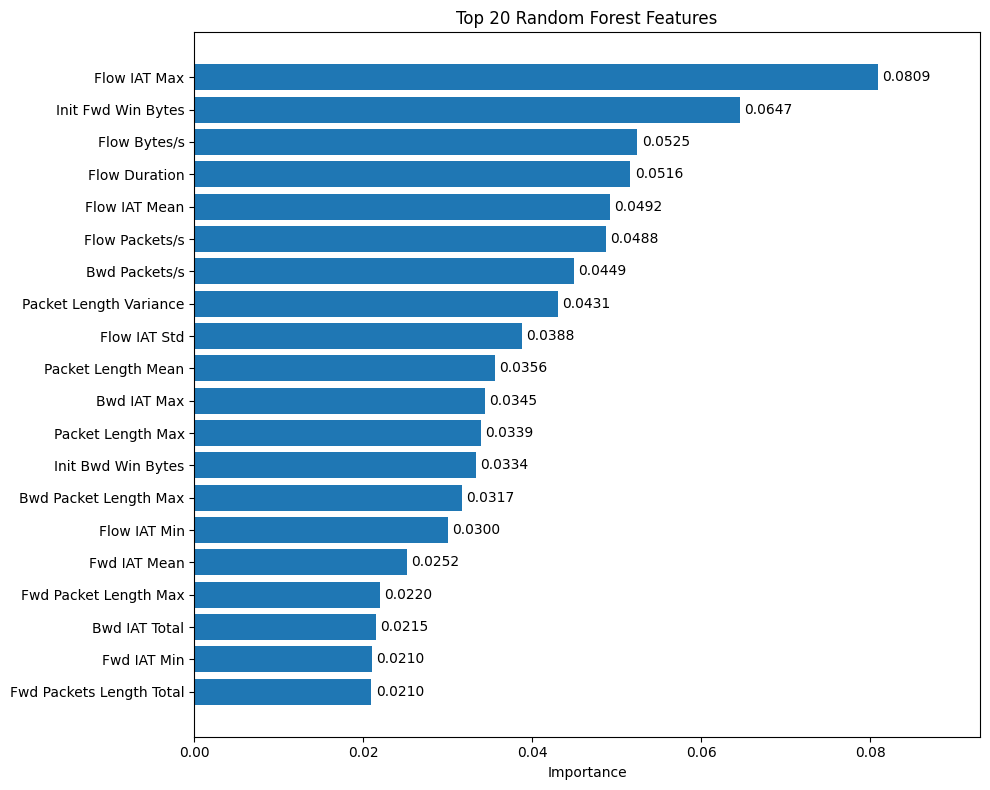

In [19]:
import matplotlib.pyplot as plt

top_features = importance.head(20)

plt.figure(figsize=(10, 8))

# 1. Lưu kết quả của plt.barh vào biến 'bars'
bars = plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

# 2. Thêm số chi tiết vào cuối mỗi thanh bar
# fmt='%.4f' để lấy 4 chữ số thập phân (có thể chỉnh thành %.3f hoặc %.2f tuỳ bạn)
plt.bar_label(bars, fmt='%.4f', padding=3)
plt.xlim(0, top_features["Importance"].max() * 1.15)

plt.title("Top 20 Random Forest Features")
plt.xlabel("Importance")

plt.tight_layout()
plt.show()

# Save model

In [20]:
joblib.dump(
    rf,
    "../Models/random_forest.joblib"
)

rf_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "FPR"
    ],
    "Value": [
        rf_accuracy,
        rf_precision,
        rf_recall,
        rf_f1,
        rf_fpr
    ]
})

rf_metrics.to_csv(
    "../Results/rf_metrics.csv",
    index=False
)

print("Random Forest saved.")

Random Forest saved.
